In [112]:
!pip install plotly

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [166]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [167]:
tickers = [
    "RELIANCE.NS",
    "HDFCBANK.NS",
    "ICICIBANK.NS",
    "INFY.NS",
    "TCS.NS",
    "ITC.NS",
    "LT.NS",
    "SBIN.NS",
    "BHARTIARTL.NS",
    "HINDUNILVR.NS"
]

In [168]:
data = yf.download(
    tickers,
    period="5y",
    interval="1d",
    auto_adjust=True
)

prices = data["Close"]

display(prices.head())

[*********************100%***********************]  10 of 10 completed


Ticker,BHARTIARTL.NS,HDFCBANK.NS,HINDUNILVR.NS,ICICIBANK.NS,INFY.NS,ITC.NS,LT.NS,RELIANCE.NS,SBIN.NS,TCS.NS
Date,,,,,,,,,,
2021-11-15,711.892456054688,728.635253906250,2215.979736328125,743.845153808594,1535.186035156250,187.477615356445,1850.477539062500,1167.531860351562,463.365203857422,3076.314941406250
2021-11-16,704.894653320312,724.307189941406,2199.437744140625,734.947448730469,1539.610107421875,185.391021728516,1858.318237304688,1140.402099609375,452.891387939453,3078.999267578125
2021-11-17,695.001159667969,716.259460449219,2185.272705078125,732.302124023438,1535.443725585938,188.579956054688,1856.037353515625,1115.989868164062,455.681335449219,3049.130126953125
2021-11-18,689.499450683594,720.283325195312,2192.812011718750,733.841308593750,1528.528808593750,187.005172729492,1802.909912109375,1120.201782226562,460.849639892578,3009.131835937500
2021-11-22,716.284118652344,709.030334472656,2182.896484375000,723.356445312500,1511.348510742188,181.808395385742,1772.021850585938,1070.584594726562,444.933013916016,2994.154296875000


In [169]:
prices.to_csv("stock_prices.csv")

In [170]:
returns = prices.pct_change().dropna()

display(returns.head())

Ticker,BHARTIARTL.NS,HDFCBANK.NS,HINDUNILVR.NS,ICICIBANK.NS,INFY.NS,ITC.NS,LT.NS,RELIANCE.NS,SBIN.NS,TCS.NS
Date,,,,,,,,,,
2021-11-16,-0.009829859377,-0.005939959591,-0.007464866179,-0.011961770582,0.002881782510,-0.011129828081,0.004237121541,-0.023236848315,-0.022603803287,0.000872578466
2021-11-17,-0.014035421613,-0.011110934151,-0.006440300072,-0.003599338581,-0.002706127880,0.017201126012,-0.001227391382,-0.021406687565,0.006160301529,-0.009700924888
2021-11-18,-0.007916114826,0.005617887048,0.003450052995,0.002101843651,-0.004503530072,-0.008350746061,-0.028624122950,0.003774150808,0.011341927003,-0.013117935067
2021-11-22,0.038846539968,-0.015623006016,-0.004521831918,-0.014287643879,-0.011239760582,-0.027789484472,-0.017132337737,-0.044293080307,-0.034537568436,-0.004977362202
2021-11-23,0.022638639919,0.000131964586,0.002365469117,-0.000199468893,-0.012788500284,0.003031642061,0.011718949935,0.009349698851,0.013671944259,0.001691691558


In [171]:
split_date = returns.index.max() - pd.DateOffset(years=1)

train_returns = returns.loc[returns.index < split_date]
test_returns = returns.loc[returns.index >= split_date]

print("Training period:", train_returns.index.min(), "to", train_returns.index.max())
print("Testing period:", test_returns.index.min(), "to", test_returns.index.max())

Training period: 2021-11-16 00:00:00 to 2025-11-12 00:00:00
Testing period: 2025-11-13 00:00:00 to 2026-11-13 00:00:00


In [172]:
mu = train_returns.mean()
cov_matrix = train_returns.cov()

In [173]:
mu_vec = mu.values.reshape(-1, 1)
ones = np.ones((len(mu), 1))
Sigma = cov_matrix.values

Sigma_inv = np.linalg.inv(Sigma)

a= (mu_vec.T @ Sigma_inv @ mu_vec)[0, 0]
c = (mu_vec.T @ Sigma_inv @ ones)[0, 0]
f= (ones.T @ Sigma_inv @ ones)[0, 0]

print("a =", a)
print("c =", c)
print("f =", f)

a = 0.01297525754204081
c = 8.530376168042425
f = 16237.864948170776


In [96]:
# Equation of the efficient frontier:
# z1 = (f*z2^2 - 2*c*z2 + a) / D
# where D = a*f - c^2

# Solving for z2:
# z2 = (c +/- sqrt(c^2 - f*(a - D*z1))) / f

In [121]:
np.random.seed(42)

num_samples = 100000
num_assets = len(mu)

random_weights = np.random.normal(
    1/num_assets, 0.12, (num_samples, num_assets)
)

random_weights += (
    1 - random_weights.sum(axis=1, keepdims=True)
) / num_assets


random_returns = random_weights @ mu.values

random_risks = np.einsum(
    'bi,ij,bj->b',
    random_weights,
    Sigma,
    random_weights
)

D = a * f - c**2

z2_values = np.linspace(0, mu.max(), 100000)
z1_values = (
    f * z2_values**2 - 2*c*z2_values + a
) / D

z2_min = c / f
z1_min = 1 / f


fig = go.Figure()

fig.add_trace(go.Scatter(
    x=random_risks,
    y=random_returns,
    mode="markers",
    marker=dict(
        color="lightblue",
        size=5,
        opacity=0.55
    ),
    name="Random Portfolios"
))

fig.add_trace(go.Scatter(
    x=z1_values,
    y=z2_values,
    mode="lines",
    line=dict(color="red", width=3),
    name="Portfolio Curve"
))

fig.add_trace(go.Scatter(
    x=[z1_min],
    y=[z2_min],
    mode="markers",
    marker=dict(color="black", size=11, symbol="star"),
    name="Minimum Variance Portfolio"
))

fig.update_layout(
    title="Bi-Criterion Portfolio Curve with Random Portfolios",
    xaxis_title="Portfolio Variance (z1)",
    yaxis_title="Expected Portfolio Return (z2)",
    width=1000,
    height=650,
    hovermode="closest"
)

fig.show()

In [174]:
z2_nd = np.linspace(c/f, mu.max(), 100000)


z1_nd = (f*z2_nd**2 - 2*c*z2_nd + a) / D

fig = go.Figure()


fig.add_trace(go.Scatter(
    x=random_risks,
    y=random_returns,
    mode="markers",
    marker=dict(color="lightblue", size=5, opacity=0.5),
    name="Random Portfolios"
))


fig.add_trace(go.Scatter(
    x=z1_nd,
    y=z2_nd,
    mode="lines",
    line=dict(color="green", width=3),
    name="Non-Dominated Frontier"
))


fig.add_trace(go.Scatter(
    x=[1/f],
    y=[c/f],
    mode="markers",
    marker=dict(color="red", size=11),
    name="Global Minimum Variance Portfolio"
))

fig.update_layout(
    title="Non-Dominated Frontier – Bi-Criterion Optimization",
    xaxis_title="Portfolio Variance (z1)",
    yaxis_title="Expected Portfolio Return (z2)",
    width=1000,
    height=650,
    hovermode="closest"
)

fig.update_xaxes(tickformat=".6f")

fig.show()

In [123]:
mu_vec = mu.values.reshape(-1, 1)
Sigma = cov_matrix.values
ones = np.ones((len(mu), 1))

Sigma_inv = np.linalg.inv(Sigma)

D = a* f - c**2

z2_values = np.linspace(c/f, mu.max(), 100000)

A1= np.column_stack((mu.values, np.ones(len(mu))))

weights_list = []

for target_return in z2_values:
    b1= np.array([target_return, 1.0])

    w = Sigma_inv @ A1 @ np.linalg.solve(
        A1.T @ Sigma_inv @ A1, b1
    )

    weights_list.append(w)

weights_array = np.array(weights_list)

weights_df = pd.DataFrame(
    weights_array,
    columns=mu.index,
    index=pd.Index(z2_values, name="Target Expected Return")
)


pd.set_option('display.float_format', '{:.12f}'.format)

display(weights_df.head())

Ticker,BHARTIARTL.NS,HDFCBANK.NS,HINDUNILVR.NS,ICICIBANK.NS,INFY.NS,ITC.NS,LT.NS,RELIANCE.NS,SBIN.NS,TCS.NS
Target Expected Return,,,,,,,,,,
0.000525337759,0.133954856212,0.126856725319,0.193370141708,0.127201730391,-0.038684950964,0.213949731416,0.012836463163,0.023689903465,0.005709579440,0.201115819850
0.000525344136,0.133958320070,0.126855434684,0.193367973932,0.127201972316,-0.038685797119,0.213951947075,0.012838079709,0.023687908768,0.005710429501,0.201113731064
0.000525350513,0.133961783928,0.126854144049,0.193365806157,0.127202214242,-0.038686643274,0.213954162734,0.012839696255,0.023685914071,0.005711279561,0.201111642278
0.000525356889,0.133965247785,0.126852853414,0.193363638381,0.127202456167,-0.038687489430,0.213956378393,0.012841312801,0.023683919374,0.005712129621,0.201109553492
0.000525363266,0.133968711643,0.126851562780,0.193361470606,0.127202698092,-0.038688335585,0.213958594052,0.012842929347,0.023681924677,0.005712979682,0.201107464706


In [124]:
investment = 100000

investment_df = weights_df * investment

display(investment_df.head())

Ticker,BHARTIARTL.NS,HDFCBANK.NS,HINDUNILVR.NS,ICICIBANK.NS,INFY.NS,ITC.NS,LT.NS,RELIANCE.NS,SBIN.NS,TCS.NS
Target Expected Return,,,,,,,,,,
0.000525337759,13395.485621233554,12685.672531872973,19337.014170753842,12720.173039125290,-3868.495096391733,21394.973141568425,1283.646316346988,2368.990346461469,570.957944017302,20111.581985011846
0.000525344136,13395.832006994187,12685.543468398348,19336.797393212073,12720.197231648350,-3868.579711914969,21395.194707486899,1283.807970930294,2368.790876775295,571.042950058430,20111.373106411051
0.000525350513,13396.178392754824,12685.414404923720,19336.580615670304,12720.221424171410,-3868.664327438205,21395.416273405375,1283.969625513599,2368.591407089120,571.127956099558,20111.164227810259
0.000525356889,13396.524778515468,12685.285341449087,19336.363838128531,12720.245616694472,-3868.748942961444,21395.637839323859,1284.131280096910,2368.391937402940,571.212962140689,20110.955349209456
0.000525363266,13396.871164276086,12685.156277974464,19336.147060586769,12720.269809217532,-3868.833558484677,21395.859405242325,1284.292934680210,2368.192467716772,571.297968181814,20110.746470608668


In [125]:
selected_indices = np.linspace(0, len(z2_values) - 1, 5, dtype=int)

gmv_idx = np.argmin(np.abs(z2_values - c/f))

portfolio_indices = sorted(set(selected_indices.tolist() + [gmv_idx]))

portfolio_values = {}

for idx in portfolio_indices:

    weights = weights_array[idx]

    daily_portfolio_returns = test_returns @ weights

    portfolio_value = investment * (1 + daily_portfolio_returns).cumprod()

    if idx == gmv_idx:
        name = "GMV Portfolio"
    else:
        name = f"Portfolio (Return={z2_values[idx]:.6f})"

    portfolio_values[name] = portfolio_value

portfolio_growth_df = pd.DataFrame(portfolio_values)

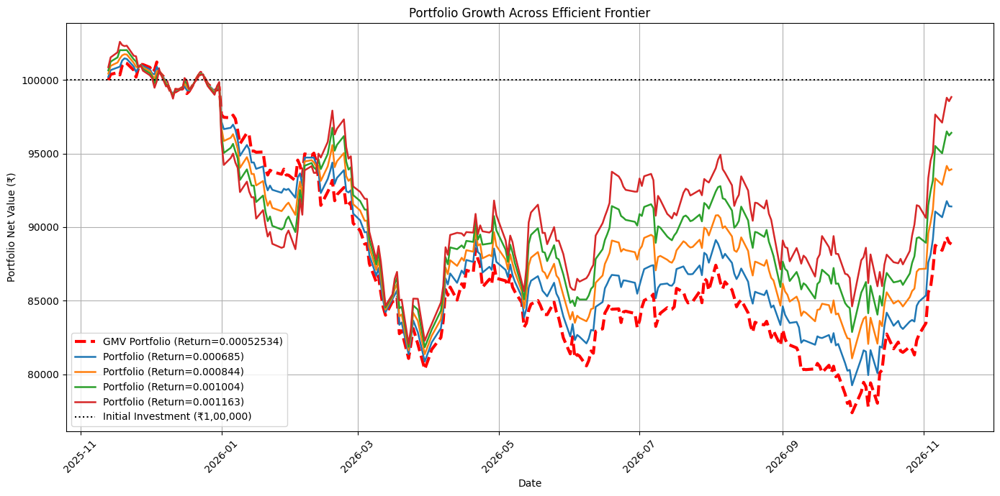

In [126]:
plt.figure(figsize=(14, 7))

for name in portfolio_growth_df.columns:

    if name == "GMV Portfolio":
        gmv_return = c / f
        plt.plot(
            portfolio_growth_df.index,
            portfolio_growth_df[name],
            color="red",
            linewidth=3,
            linestyle="--",
            label=f"GMV Portfolio (Return={gmv_return:.8f})"
        )
    else:
        plt.plot(
            portfolio_growth_df.index,
            portfolio_growth_df[name],
            linewidth=1.8,
            label=name
        )

plt.axhline(
    investment,
    color="black",
    linestyle=":",
    label="Initial Investment (₹1,00,000)"
)

plt.xlabel("Date")
plt.ylabel("Portfolio Net Value (₹)")
plt.title("Portfolio Growth Across Efficient Frontier")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

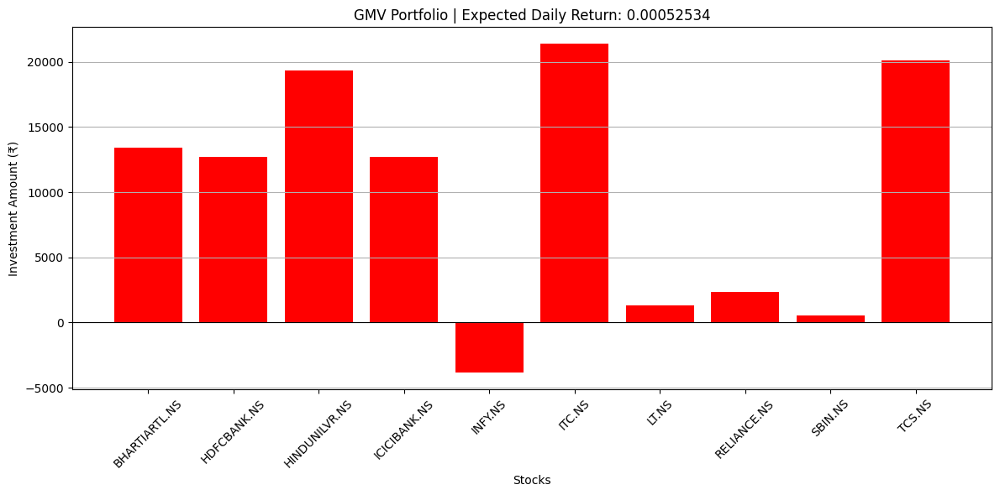

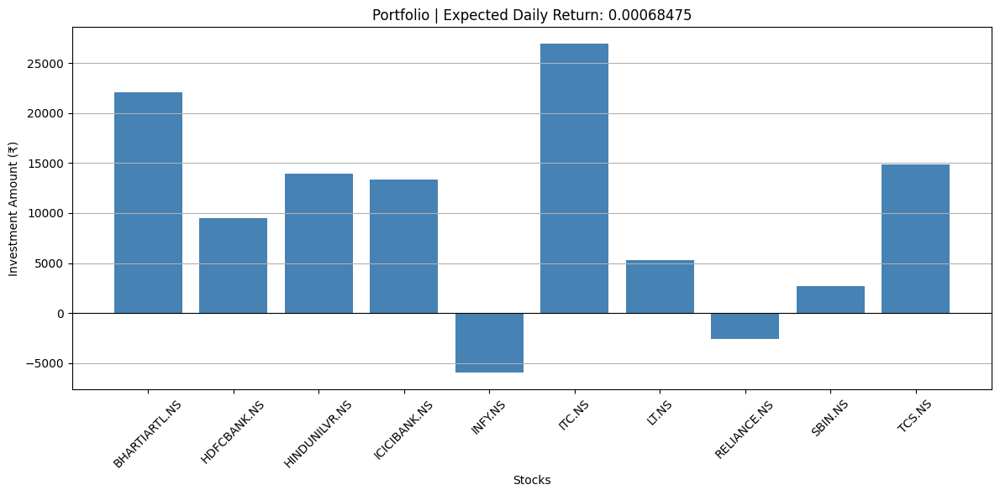

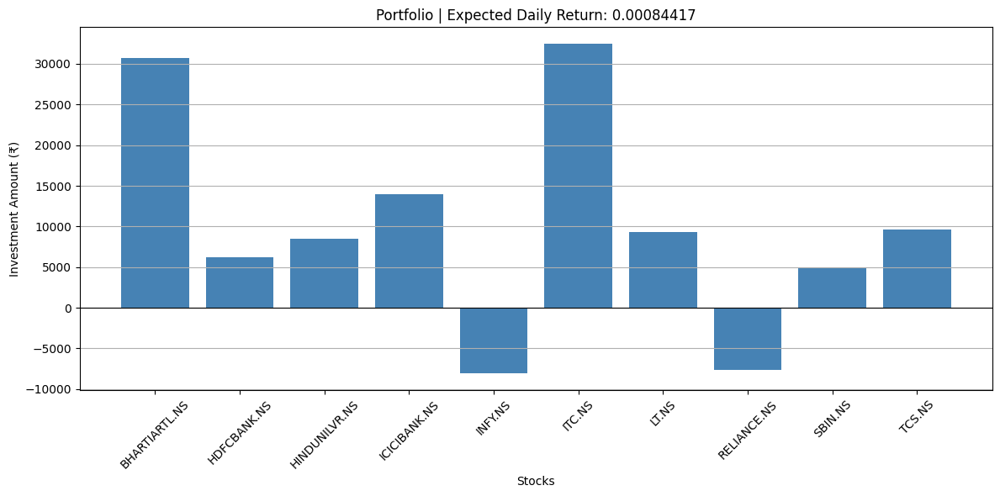

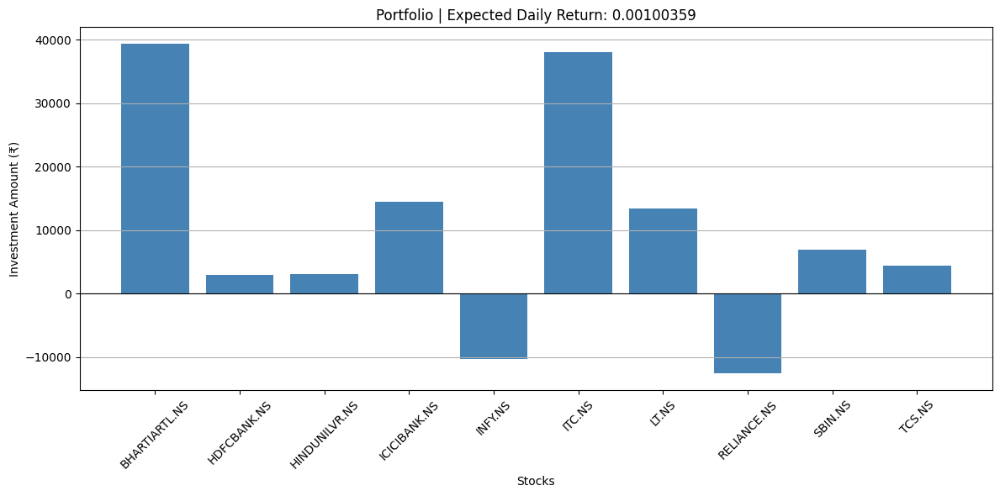

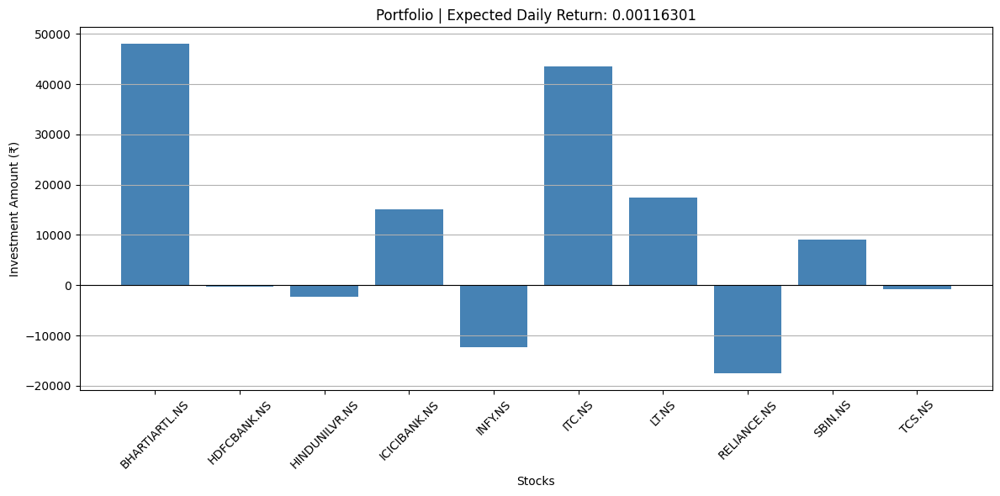

In [127]:
for idx in portfolio_indices:

    plt.figure(figsize=(12, 6))

    allocation = investment_df.iloc[idx]

    if idx == gmv_idx:
        title = f"GMV Portfolio | Expected Daily Return: {c/f:.8f}"
        color = "red"
    else:
        title = f"Portfolio | Expected Daily Return: {z2_values[idx]:.8f}"
        color = "steelblue"

    plt.bar(
        allocation.index,
        allocation.values,
        color=color
    )

    plt.axhline(0, color="black", linewidth=0.8)

    plt.xlabel("Stocks")
    plt.ylabel("Investment Amount (₹)")
    plt.title(title)

    plt.xticks(rotation=45)
    plt.grid(axis="y")
    plt.tight_layout()
    plt.show()

In [ ]:
gmv_2d_weights=weights_array[0]

In [129]:
gmv_2d_weights

array([ 0.13395486,  0.12685673,  0.19337014,  0.12720173, -0.03868495,
        0.21394973,  0.01283646,  0.0236899 ,  0.00570958,  0.20111582])

In [105]:
####3 d case#### lets gooooo

In [130]:
import re

with open("esg_scores_clean .txt", "r", encoding="utf-8") as f:
    text = f.read()

records = []
current_year = None

for line in text.splitlines():

    year_match = re.search(r"^(2021|2022|2023|2024|2025|2026)", line.strip())

    if year_match and "ESG" in line.upper():
        current_year = int(year_match.group(1))
        continue

    match = re.match(
        r"^\s*([A-Z]+\.NS)\s+(.+?)\s+(\d{1,3})\s+"
        r"(Leadership|Strong|Adequate)\b",
        line
    )

    if match and current_year:
        ticker, company, score, classification = match.groups()

        records.append({
            "Ticker": ticker,
            "Company": company.strip(),
            "Year": current_year,
            "ESG_Score": int(score),
            "Classification": classification
        })

esg_df = pd.DataFrame(records)

display(esg_df)

,Ticker,Company,Year,ESG_Score,Classification
0,INFY.NS,Infosys Limited,2021,79,Leadership
1,ICICIBANK.NS,ICICI Bank Limited,2021,78,Leadership
2,BHARTIARTL.NS,Bharti Airtel Limited,2021,77,Leadership
3,HINDUNILVR.NS,Hindustan Unilever Limited,2021,75,Leadership
4,HDFCBANK.NS,HDFC Bank Limited,2021,73,Leadership
5,SBIN.NS,State Bank of India,2021,73,Leadership
6,TCS.NS,Tata Consultancy Services Limited,2021,65,Strong
7,ITC.NS,ITC Limited,2021,65,Strong
8,LT.NS,Larsen & Toubro Limited,2021,64,Strong
9,RELIANCE.NS,Reliance Industries Limited,2021,61,Strong


In [131]:
esg_matrix = esg_df.pivot_table(
    index="Ticker",
    columns="Year",
    values="ESG_Score",
    aggfunc="first"
)

esg_matrix = esg_matrix.reindex(tickers)

display(esg_matrix)

Year,2021,2022,2023,2024,2025,2026
Ticker,,,,,,
RELIANCE.NS,61,61,52,55,55,55
HDFCBANK.NS,73,73,71,71,73,73
ICICIBANK.NS,78,78,68,69,69,69
INFY.NS,79,79,77,76,76,76
TCS.NS,65,65,75,74,74,74
ITC.NS,65,65,62,63,63,63
LT.NS,64,64,60,61,61,61
SBIN.NS,73,73,65,68,68,68
BHARTIARTL.NS,77,77,59,58,57,57


In [132]:
esg_scores = esg_matrix[2025].reindex(mu.index)

esg_vector = esg_scores.values.reshape(-1, 1)

print(esg_vector)

[[57]
 [73]
 [64]
 [69]
 [76]
 [63]
 [61]
 [55]
 [68]
 [74]]


In [133]:
print("Total records:", len(esg_df))
print("Unique companies:", esg_df["Ticker"].nunique())
print("Years:", sorted(esg_df["Year"].unique()))

print("\nMissing ESG scores:")
print(esg_matrix.isnull().sum())

Total records: 60
Unique companies: 10
Years: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]

Missing ESG scores:
Year
2021    0
2022    0
2023    0
2024    0
2025    0
2026    0
dtype: int64


In [134]:
mu_vec = mu.values.reshape(-1, 1)
q = esg_scores.values.reshape(-1, 1)

ones = np.ones((len(mu_vec), 1))

Sigma = cov_matrix.values
Sigma_inv = np.linalg.inv(Sigma)

a = (mu_vec.T @ Sigma_inv @ mu_vec)[0, 0]
b = (mu_vec.T @ Sigma_inv @ q)[0, 0]
c = (mu_vec.T @ Sigma_inv @ ones)[0, 0]

d = (q.T @ Sigma_inv @ q)[0, 0]
e = (q.T @ Sigma_inv @ ones)[0, 0]

f = (ones.T @ Sigma_inv @ ones)[0, 0]

M = np.array([
    [a, b, c],
    [b, d, e],
    [c, e, f]
])

print("a =", a)
print("b =", b)
print("c =", c)
print("d =", d)
print("e =", e)
print("f =", f)

print("\nFinal Matrix:")
print(M)

a = 0.0129752521035738
b = 494.0517544921779
c = 8.530364895537993
d = 73655066.27211641
e = 1070792.2695291382
f = 16237.867442736731

Final Matrix:
[[1.29752521e-02 4.94051754e+02 8.53036490e+00]
 [4.94051754e+02 7.36550663e+07 1.07079227e+06]
 [8.53036490e+00 1.07079227e+06 1.62378674e+04]]


In [135]:
esg_scores = esg_matrix[2025].reindex(mu.index)

assert esg_scores.notna().all()
assert list(cov_matrix.index) == list(mu.index)
assert list(esg_scores.index) == list(mu.index)

In [136]:
det_C = np.linalg.det(M)

minor_1 = M[0, 0]
minor_2 = np.linalg.det(M[:2, :2])
minor_3 = det_C

print("First minor:", minor_1)
print("Second minor:", minor_2)
print("Third minor:", minor_3)

if minor_1 > 0 and minor_2 > 0 and minor_3 > 0:
    print("C is Positive Definite")
else:
    print("C is NOT Positive Definite")

First minor: 0.0129752521035738
Second minor: 711605.9174693476
Third minor: 343505147.1789861
C is Positive Definite


In [90]:
C_inv = np.linalg.inv(M)

print("Determinant of C:", det_C)
print("\nInverse of C:")
print(C_inv)

Determinant of C: 343504780.57440305

Inverse of C:
[[ 1.43826469e+02  3.23692995e-03 -2.89014097e-01]
 [ 3.23692995e-03  4.01517455e-07 -2.81782039e-05]
 [-2.89014097e-01 -2.81782039e-05  2.07160190e-03]]


In [137]:
det_C = np.linalg.det(M)


v1 = Sigma_inv @ mu_vec
v2 = Sigma_inv @ q
v3 = Sigma_inv @ ones

# x0
x0 = (
    (b*e - c*d)*v1
    + (b*c - a*e)*v2
    + (a*d - b**2)*v3
) / det_C

# d2
d2 = (
    (d*f - e**2)*v1
    + (c*e - b*f)*v2
    + (b*e - c*d)*v3
) / det_C

# d3
d3 = (
    (c*e - b*f)*v1
    + (a*f - c**2)*v2
    + (b*c - a*e)*v3
) / det_C

print("x0:\n", x0)
print("\nd2:\n", d2)
print("\nd3:\n", d3)

x0:
 [[ 0.52450213]
 [-1.12162323]
 [ 1.51175579]
 [-0.78300758]
 [-0.81435399]
 [-0.45320346]
 [ 0.49712717]
 [ 3.09828534]
 [-1.16182958]
 [-0.29765258]]

d2:
 [[ 465.55787922]
 [ -46.76594312]
 [-470.8830723 ]
 [ 140.20816368]
 [ -35.58251647]
 [ 403.12968713]
 [ 182.57611864]
 [-647.12084286]
 [ 259.38113028]
 [-250.50060421]]

d3:
 [[-0.00963122]
 [ 0.01930494]
 [-0.01624121]
 [ 0.01268578]
 [ 0.01204598]
 [ 0.00690545]
 [-0.00879843]
 [-0.04146901]
 [ 0.01563864]
 [ 0.00955909]]


In [138]:
A = (d2.T @ Sigma @ d2).item()
B = (d2.T @ Sigma @ d3).item()
C = (d3.T @ Sigma @ d3).item()
D = (d2.T @ Sigma @ x0).item()
E = (d3.T @ Sigma @ x0).item()
F = (x0.T @ Sigma @ x0).item()

print("Six coefficients:")
print("A =", A)
print("B =", B)
print("C =", C)
print("D =", D)
print("E =", E)
print("F =", F)

Six coefficients:
A = 143.82642744945474
B = 0.0032369293334924866
C = 4.015174141510858e-07
D = -0.28901398731275657
E = -2.8178203395467397e-05
F = 0.002071601905570735


In [139]:
z2_values = np.linspace(mu.min(), mu.max(), 100)
z3_values = np.linspace(q.min(), q.max(), 100)

Z2, Z3 = np.meshgrid(z2_values, z3_values)

g2 = (
    (d*f - e**2)*Z2
    + (c*e - b*f)*Z3
    + (b*e - c*d)
) / det_C

g3 = (
    (c*e - b*f)*Z2
    + (a*f - c**2)*Z3
    + (b*c - a*e)
) / det_C

g4 = (
    (b*e - c*d)*Z2
    + (b*c - a*e)*Z3
    + (a*d - b**2)
) / det_C

In [140]:
Z1 = (
    A * Z2**2
    + 2 * B * Z2 * Z3
    + C * Z3**2
    + 2 * D * Z2
    + 2 * E * Z3
    + F
)

In [141]:
Z1_check = np.zeros_like(Z1)

for i in range(Z2.shape[0]):
    for j in range(Z2.shape[1]):

        weights = x0 + Z2[i, j]*d2 + Z3[i, j]*d3

        Z1_check[i, j] = (
            weights.T @ Sigma @ weights
        ).item()

print("Maximum difference:",
      np.max(np.abs(Z1 - Z1_check)))

Maximum difference: 1.2739375526704677e-18


In [142]:
fig = go.Figure()


fig.add_trace(go.Surface(
    x=Z2,
    y=Z3,
    z=Z1,
    colorscale="Viridis",
    opacity=0.85,
    name="Efficient Surface",
    colorbar=dict(title="Variance")
))


fig.add_trace(go.Scatter3d(
    x=random_weights @ mu.values,
    y=random_weights @ q.flatten(),
    z=np.einsum('bi,ij,bj->b', random_weights, Sigma, random_weights),
    mode="markers",
    marker=dict(
        size=3,
        color="black",
        opacity=0.5
    ),
    name="Random Portfolios"
))

fig.update_layout(
    title="Three-Criteria Portfolio Efficient Surface",
    scene=dict(
        xaxis_title="Expected Return (z2)",
        yaxis_title="ESG Score (z3)",
        zaxis_title="Portfolio Variance (z1)"
    ),
    width=1100,
    height=850
)

fig.show()

In [143]:
fig = go.Figure()

# Projection of the 3D surface onto Return vs Variance
fig.add_trace(go.Scatter(
    x=Z2.flatten(),
    y=Z1.flatten(),
    mode="markers",
    marker=dict(
        size=3,
        color="blue",
        opacity=0.25
    ),
    name="Projected 3D Surface"
))

# Minimum variance envelope across ESG scores
fig.add_trace(go.Scatter(
    x=Z2[0, :],
    y=np.nanmin(Z1, axis=0),
    mode="lines",
    line=dict(color="red", width=3),
    name="Minimum Variance Projection"
))

# Random portfolio dots
fig.add_trace(go.Scatter(
    x=random_weights @ mu.values,
    y=np.einsum(
        'bi,ij,bj->b',
        random_weights, Sigma, random_weights
    ),
    mode="markers",
    marker=dict(
        size=5,
        color="black",
        opacity=0.4
    ),
    name="Random Portfolios"
))

fig.update_layout(
    title="2D Projection of 3D Surface: Expected Return vs Variance",
    xaxis_title="Expected Daily Return (z2)",
    yaxis_title="Portfolio Variance (z1)",
    width=1000,
    height=700,
    hovermode="closest"
)

fig.show()

In [144]:
H = np.array([
    [A, B],
    [B, C]
])

rhs = np.array([-D, -E])


print("Hessian eigenvalues:", np.linalg.eigvalsh(H))

if np.all(np.linalg.eigvalsh(H) > 0):

    z2_min, z3_min = np.linalg.solve(H, rhs)

    z1_min = (
        A*z2_min**2
        + 2*B*z2_min*z3_min
        + C*z3_min**2
        + 2*D*z2_min
        + 2*E*z3_min
        + F
    )

    print("Minimum Variance Point:")
    print("z2* (Expected Return) =", z2_min)
    print("z3* (ESG Score) =", z3_min)
    print("z1* (Minimum Variance) =", z1_min)

else:
    print("Hessian is not positive definite.")

Hessian eigenvalues: [3.28667718e-07 1.43826428e+02]
Minimum Variance Point:
z2* (Expected Return) = 0.0005253377591374352
z3* (ESG Score) = 65.94414403894572
z1* (Minimum Variance) = 6.158444164706522e-05


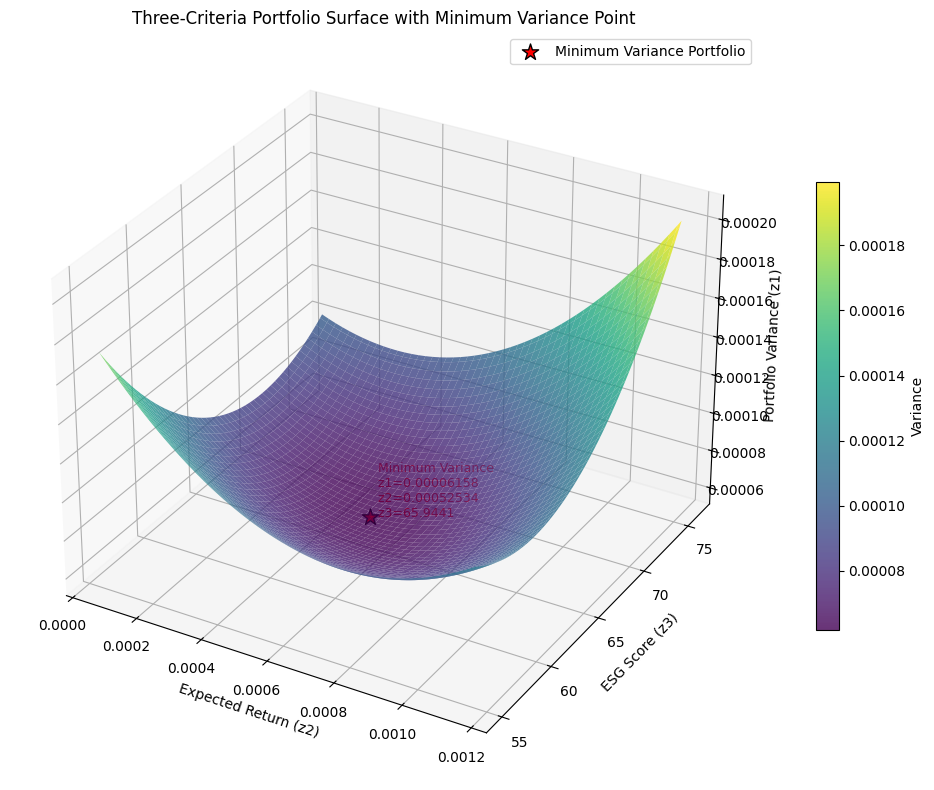

In [145]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

surface = ax.plot_surface(
    Z2,
    Z3,
    Z1,
    cmap="viridis",
    edgecolor="none",
    alpha=0.8
)

# Highlight minimum variance point
ax.scatter(
    z2_min,
    z3_min,
    z1_min,
    color="red",
    s=150,
    marker="*",
    edgecolors="black",
    label="Minimum Variance Portfolio"
)

# Label the point
ax.text(
    z2_min,
    z3_min,
    z1_min,
    f"  Minimum Variance\n  z1={z1_min:.8f}\n  z2={z2_min:.8f}\n  z3={z3_min:.4f}",
    color="red",
    fontsize=9
)

ax.set_xlabel("Expected Return (z2)")
ax.set_ylabel("ESG Score (z3)")
ax.set_zlabel("Portfolio Variance (z1)")

ax.set_title("Three-Criteria Portfolio Surface with Minimum Variance Point")

fig.colorbar(surface, ax=ax, shrink=0.6, label="Variance")
ax.legend()

plt.tight_layout()
plt.show()

In [146]:
condition1 = A*(Z2 - z2_min) + B*(Z3 - z3_min) >= -1e-10

condition2 = B*(Z2 - z2_min) + C*(Z3 - z3_min) >= -1e-10

nondominated_mask = condition1 & condition2


Z2_nd = np.where(nondominated_mask, Z2, np.nan)
Z3_nd = np.where(nondominated_mask, Z3, np.nan)
Z1_nd = np.where(nondominated_mask, Z1, np.nan)



fig = go.Figure()

# Candidate non-dominated surface
fig.add_trace(go.Surface(
    x=Z2_nd,
    y=Z3_nd,
    z=Z1_nd,
    colorscale="Viridis",
    opacity=0.85,
    colorbar=dict(title="Variance"),
    name="Candidate Non-Dominated Surface"
))


fig.add_trace(go.Scatter3d(
    x=random_weights @ mu.values,
    y=random_weights @ q.flatten(),
    z=np.einsum(
        'bi,ij,bj->b',
        random_weights, Sigma, random_weights
    ),
    mode="markers",
    marker=dict(
        size=3,
        color="black",
        opacity=0.5
    ),
    name="Random Portfolios"
))


fig.add_trace(go.Scatter3d(
    x=[z2_min],
    y=[z3_min],
    z=[z1_min],
    mode="markers+text",
    marker=dict(
        color="red",
        size=10,
        symbol="diamond",
        line=dict(color="black", width=2)
    ),
    text=["Minimum Variance Portfolio"],
    textposition="top right",
    name="Minimum Variance Portfolio",
    hovertemplate=(
        "Expected Return: %{x:.8f}<br>"
        "ESG Score: %{y:.4f}<br>"
        "Variance: %{z:.8f}"
        "<extra></extra>"
    )
))

fig.update_layout(
    title="Candidate Non-Dominated Portfolio Surface",
    scene=dict(
        xaxis_title="Expected Return (z2)",
        yaxis_title="ESG Score (z3)",
        zaxis_title="Portfolio Variance (z1)"
    ),
    width=1100,
    height=850
)

fig.show()

In [147]:
print("Total simulated points:", Z2.size)
print("Candidate non-dominated points:", np.sum(nondominated_mask))
print("Candidate non-dominated percentage:",
      np.mean(nondominated_mask)*100, "%")

Total simulated points: 10000
Candidate non-dominated points: 3967
Candidate non-dominated percentage: 39.67 %


In [148]:
nd_indices = np.argwhere(nondominated_mask)

selected_positions = np.linspace(
    0, len(nd_indices)-1, 5, dtype=int
)

selected_indices = nd_indices[selected_positions]

investment = 100000

portfolio_weights = []
portfolio_names = []

for k, (i, j) in enumerate(selected_indices):

    target_return = Z2[i, j]
    target_esg = Z3[i, j]

    weights = (
        x0
        + target_return*d2
        + target_esg*d3
    ).flatten()

    portfolio_weights.append(weights)

    portfolio_names.append(
        f"Portfolio {k+1}"
    )

weights_df = pd.DataFrame(
    portfolio_weights,
    index=portfolio_names,
    columns=mu.index
)

display(weights_df)

Ticker,BHARTIARTL.NS,HDFCBANK.NS,HINDUNILVR.NS,ICICIBANK.NS,INFY.NS,ITC.NS,LT.NS,RELIANCE.NS,SBIN.NS,TCS.NS
Portfolio 1,0.473842842092,0.000940031708,-0.020369181710,0.151557261919,-0.121265600812,0.431962673167,0.171259881443,-0.174208918954,0.089952269291,-0.003671258144
Portfolio 2,0.411454377217,0.116120514329,-0.111587977733,0.225341601647,-0.049323497682,0.468487244601,0.116969217552,-0.413302793698,0.179947588233,0.055893725535
Portfolio 3,0.264699491275,0.193098519491,-0.051337824165,0.234043720438,0.000277962586,0.393152440494,0.042374603392,-0.395493939893,0.169472764861,0.149712261520
Portfolio 4,0.308685858574,0.243136763922,-0.172987760553,0.293577401281,0.030502972579,0.476514111278,0.044712570323,-0.619541166574,0.256356578139,0.139042671032
Portfolio 5,0.333975735652,0.291163330149,-0.270215890589,0.344174225802,0.059757889474,0.540452538716,0.040783546745,-0.805964270408,0.328368303967,0.137504590493


In [149]:
investment_df = weights_df * investment

display(investment_df)

Ticker,BHARTIARTL.NS,HDFCBANK.NS,HINDUNILVR.NS,ICICIBANK.NS,INFY.NS,ITC.NS,LT.NS,RELIANCE.NS,SBIN.NS,TCS.NS
Portfolio 1,47384.284209215119,94.003170778412,-2036.918170960689,15155.726191866348,-12126.560081150739,43196.267316718971,17125.988144321414,-17420.891895434299,8995.226929051958,-367.125814406410
Portfolio 2,41145.437721731170,11612.051432876624,-11158.797773270235,22534.160164653760,-4932.349768249144,46848.724460107907,11696.921755158384,-41330.279369813419,17994.758823342559,5589.372553462435
Portfolio 3,26469.949127525604,19309.851949120250,-5133.782416463295,23404.372043808176,27.796258573543,39315.244049444067,4237.460339229915,-39549.393989334189,16947.276486073017,14971.226152023077
Portfolio 4,30868.585857368937,24313.676392189154,-17298.776055283804,29357.740128118548,3050.297257862955,47651.411127798128,4471.257032283615,-61954.116657407976,25635.657813896429,13904.267103174107
Portfolio 5,33397.573565176295,29116.333014916519,-27021.589058907924,34417.422580236802,5975.788947354732,54045.253871591427,4078.354674450835,-80596.427040830458,32836.830396685757,13750.459049326169


In [150]:
portfolio_growth = pd.DataFrame(
    index=test_returns.index
)

for name in weights_df.index:

    weights = weights_df.loc[name].values

    daily_returns = test_returns @ weights

    portfolio_value = (
        investment * (1 + daily_returns).cumprod()
    )

    portfolio_growth[name] = portfolio_value

display(portfolio_growth)

,Portfolio 1,Portfolio 2,Portfolio 3,Portfolio 4,Portfolio 5
Date,,,,,
2025-11-13,100853.546652525532,100783.311616956300,100435.669815069487,100608.632369474843,100726.189406289763
2025-11-14,101517.018213661722,101149.206858681253,100622.935320979435,100653.461089030257,100637.205800019292
2025-11-17,101858.917897707361,101615.715451403841,101031.183030223809,101210.662930585357,101314.660210059505
2025-11-18,102556.664606323451,102071.185902669997,101097.650034744962,101326.674530312404,101441.680567446150
2025-11-19,102348.953935014637,102212.152345775292,101646.809487106584,101905.369753403938,102077.219708347751
...,...,...,...,...,...
2026-11-06,97508.950050609346,97346.085537953870,93903.208814681755,95620.702736568477,96527.156701539221
2026-11-09,96964.102532845121,96929.605191065799,93596.107981214096,95353.776261300358,96304.133809072839
2026-11-11,98640.793051477420,98406.058202829387,94721.335588003712,96533.119267154572,97498.752941430968


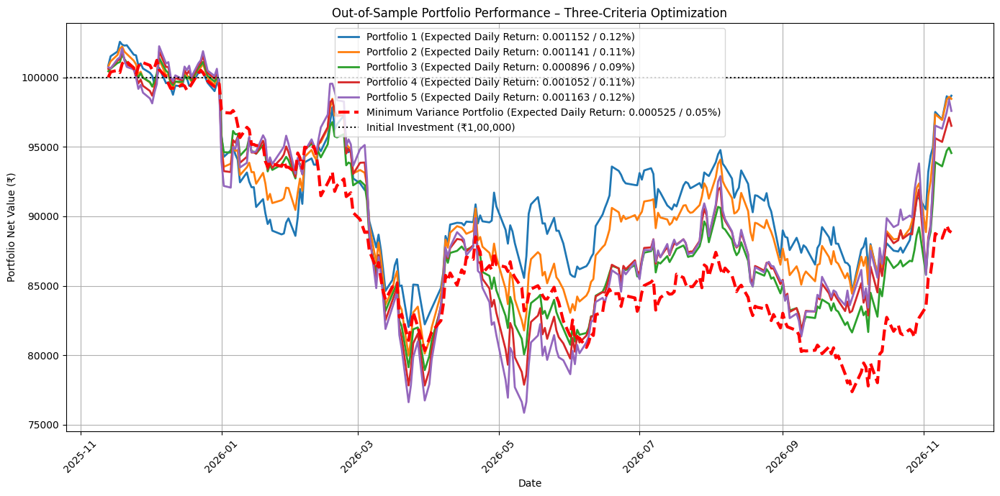

In [151]:
min_variance_weights = (
    x0 + z2_min * d2 + z3_min * d3
).flatten()


min_variance_returns = test_returns @ min_variance_weights

portfolio_growth["Minimum Variance Portfolio"] = (
    investment * (1 + min_variance_returns).cumprod()
)


plt.figure(figsize=(14, 7))

for name in portfolio_growth.columns:
    if name == "Minimum Variance Portfolio":
        plt.plot(
            portfolio_growth.index,
            portfolio_growth[name],
            color="red",
            linewidth=3,
            linestyle="--",
            label=f"Minimum Variance Portfolio (Expected Daily Return: {z2_min:.6f} / {z2_min:.2%})"
        )
    else:
        plt.plot(
            portfolio_growth.index,
            portfolio_growth[name],
            linewidth=2,
            label=f"{name} (Expected Daily Return: {weights_df.loc[name].values @ mu.values:.6f} / {(weights_df.loc[name].values @ mu.values):.2%})"
        )

plt.axhline(
    investment,
    color="black",
    linestyle=":",
    label="Initial Investment (₹1,00,000)"
)

plt.xlabel("Date")
plt.ylabel("Portfolio Net Value (₹)")
plt.title("Out-of-Sample Portfolio Performance – Three-Criteria Optimization")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [152]:
performance = pd.DataFrame(index=portfolio_growth.columns)

performance["Initial Investment"] = investment

performance["Final Value"] = portfolio_growth.iloc[-1]

performance["Profit/Loss"] = (
    performance["Final Value"] - investment
)

performance["Total Return (%)"] = (
    performance["Profit/Loss"] / investment
) * 100

display(performance.round(2))

,Initial Investment,Final Value,Profit/Loss,Total Return (%)
Portfolio 1,100000,98678.779999999999,-1321.220000000000,-1.320000000000
Portfolio 2,100000,98450.789999999994,-1549.210000000000,-1.550000000000
Portfolio 3,100000,94550.940000000002,-5449.060000000000,-5.450000000000
Portfolio 4,100000,96509.210000000006,-3490.790000000000,-3.490000000000
Portfolio 5,100000,97582.770000000004,-2417.230000000000,-2.420000000000
Minimum Variance Portfolio,100000,88844.309999999998,-11155.690000000001,-11.160000000000


In [154]:
d3_case=min_variance_weights
d3_case

array([ 0.13395486,  0.12685673,  0.19337014,  0.12720173, -0.03868495,
        0.21394973,  0.01283646,  0.0236899 ,  0.00570958,  0.20111582])

In [155]:
gmv_2d_weights

array([ 0.13395486,  0.12685673,  0.19337014,  0.12720173, -0.03868495,
        0.21394973,  0.01283646,  0.0236899 ,  0.00570958,  0.20111582])